In [1]:
from visualize import *
from data_generation import *   
from preprocessing import *
from sb import loss
from sb import model
from datasets.dataset import *
from torch.utils.data import DataLoader
import torch.nn.functional as F

In [2]:
high_resol_coef = 0.01 # 점성 계수 작게
low_resol_coef = 0.1 # 점성 계수 크게

high_f_1d = generate_dataset(n_samples=40, nu=high_resol_coef, Nx=512, Nt=512, T=1.0, L=1.0, seed=0, warmup_steps=100)
print("GT high PDE (before downsampling) :", loss.burgers_residual(torch.tensor(high_f_1d), high_resol_coef))
high_f_1d = high_f_1d[:,:,::4,::4]
low_f_1d = generate_dataset(n_samples=40, nu=low_resol_coef, Nx=128, Nt=128, T=1.0, L=1.0, U0=high_f_1d[:,:,[0], :], seed=20)
print("GT low PDE (after downsampling) :", loss.burgers_residual(torch.tensor(low_f_1d), low_resol_coef), "GT high PDE (after downsampling) :", loss.burgers_residual(torch.tensor(high_f_1d), high_resol_coef))
# low_f_1d, high_f_1d = make_paired_time_window_dataset(low_f_1d, high_f_1d, win_T=128, stride=128)
# print("GT low PDE (after downsampling) :", loss.burgers_residual(torch.tensor(low_f_1d), low_resol_coef), "GT high PDE (after downsampling) :", loss.burgers_residual(torch.tensor(high_f_1d), high_resol_coef))
mask_low_1d = make_sensor_mask(low_f_1d, n_sensors=13, sparse_ratio=None, seed=0)
mask_high_1d = make_sensor_mask(high_f_1d, n_sensors=13, sparse_ratio=None, seed=0)

# dataset_visualization(low_f_1d, mask_low_1d, batch_idx=0)
# dataset_visualization(high_f_1d, mask_high_1d, batch_idx=0)

100%|██████████| 40/40 [00:01<00:00, 24.97it/s]


GT high PDE (before downsampling) : tensor(0.0004)


100%|██████████| 40/40 [00:00<00:00, 161.48it/s]

GT low PDE (after downsampling) : tensor(0.0490) GT high PDE (after downsampling) : tensor(0.0590)


In [3]:
# # 코드 작성을 위해 임의로 만든 샘플 데이터임. 추후 시뮬 데이터로 교체 예정
# high = np.load("./data_test/NS-Re1000_T255.npy", mmap_mode="r")
# high_f_2d = np.concatenate([high] * 10, axis=0)

# low = np.load("./data_test/NS-Re1000_T255.npy", mmap_mode="r")
# low_f_2d = np.concatenate([low] * 10, axis=0)

# mask_high_2d = make_sensor_mask(high_f_2d, n_sensors=int(256*256*0.1), sparse_ratio=None, seed=0)
# mask_low_2d = make_sensor_mask(low_f_2d, n_sensors=int(256*256*0.1), sparse_ratio=None, seed=0)

# ds_2d = PDEPairDataset(low_f_2d, high_f_2d, None, mask_high_2d)
# dl_2d = DataLoader(ds_2d, batch_size=2, shuffle=True, drop_last=False)

In [4]:
N = low_f_1d.shape[0]
train_ratio = 0.8
val_ratio = 0.1

N_train = int(N * train_ratio)
N_val = int(N * val_ratio)
N_test = N - N_train - N_val

low_train  = low_f_1d[:N_train]
high_train = high_f_1d[:N_train]
mask_train = mask_high_1d[:N_train]

low_val  = low_f_1d[N_train:N_train + N_val]
high_val = high_f_1d[N_train:N_train + N_val]
mask_val = mask_high_1d[N_train:N_train + N_val]

low_test  = low_f_1d[N_train + N_val:]
high_test = high_f_1d[N_train + N_val:]
mask_test = mask_high_1d[N_train + N_val:]

ds_train = PDEPairDataset(low_data=low_train, high_data=high_train, mask_low_data=None, mask_high_data=mask_train)
dl_train = DataLoader(ds_train, batch_size=8, shuffle=True, drop_last=False)

ds_val = PDEPairDataset(low_data=low_val, high_data=high_val, mask_low_data=None, mask_high_data=mask_val)
dl_val = DataLoader(ds_val, batch_size=4, shuffle=False, drop_last=False)

ds_test = PDEPairDataset(low_data=low_test, high_data=high_test, mask_low_data=None, mask_high_data=mask_test)
dl_test = DataLoader(ds_test, batch_size=4, shuffle=False, drop_last=False)

In [5]:
sb_object = model.SB_model_ver1(dl_train, dl_val, [0,1], time_dim=8, steps=10, base_lr=1e-4, save=True, pde_type='burgers')

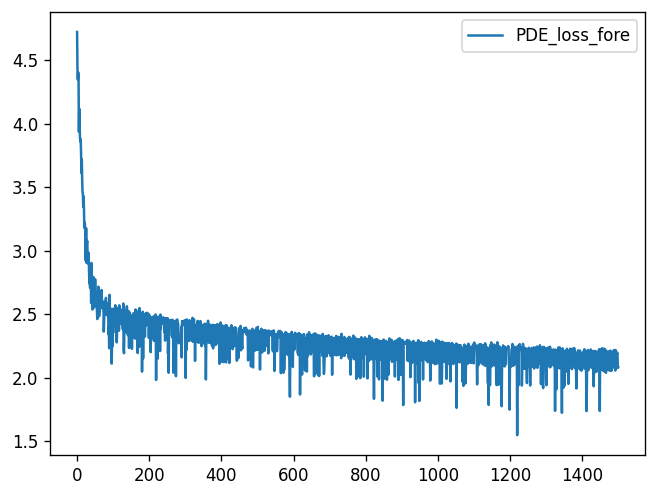

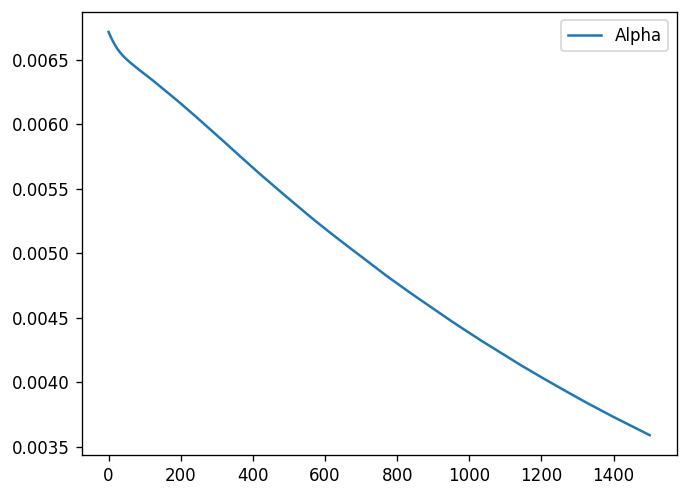

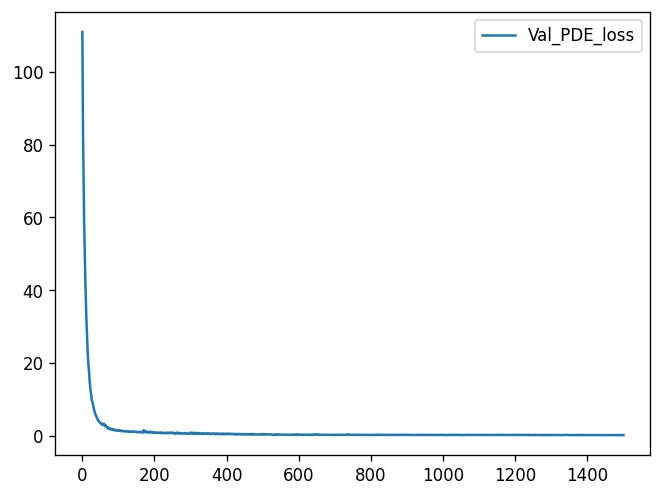

processed: 1501:   2%|▏         | 1556/100000 [12:00<7:42:39,  3.55it/s, MSE_observed=0.33411002, PDE_loss=7.0362463, Val_PDE_loss=0.296, Alpha=0.0035897177]

In [ ]:
sb_object.train(train_epochs=100000, model_name='40sample_try_unknown_alpha.pt', known_alpha=None)

In [7]:
models_dict=torch.load('./model/40sample_try_unknown_alpha.pt')
sb_object.v_fore.load_state_dict(models_dict['v_fore'])
sb_object.time_embed.load_state_dict(models_dict['time_embed'])

<All keys matched successfully>

In [ ]:
sb_object.v_fore.eval()
sb_object.time_embed.eval()

x0_chunks = []
m0_chunks = []
x1_chunks = []
m1_chunks = []
pred_chunks = []
with torch.no_grad():
    for x_0, x_1, mask_low, mask_high in dl_train:
        pred = sb_object.eval_fore(x_0=x_0, x_1=x_1, mask_low=mask_low, mask_high=mask_high)
        x0_chunks.append(x_0.detach().cpu())
        x1_chunks.append(x_1.detach().cpu())
        m0_chunks.append(mask_low.detach().cpu())
        m1_chunks.append(mask_high.detach().cpu())
        pred_chunks.append(pred.detach().cpu())

x0_all = torch.cat(x0_chunks, dim=0)
x1_all = torch.cat(x1_chunks, dim=0)
m0_all = torch.cat(m0_chunks, dim=0)
m1_all = torch.cat(m1_chunks, dim=0)
pred_all = torch.cat(pred_chunks, dim=0)
nwin, C, win_T, X = pred_all.shape
x0_stitched = x0_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
x1_stitched = x1_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
m0_stitched = m0_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
m1_stitched = m1_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
pred_stitched = pred_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
estimated_coef = F.softplus(sb_object.alpha).detach().cpu().numpy()
x1_predict_initial = generate_dataset(nu=estimated_coef, Nx=128, Nt=128, T=1.0, L=1.0, seed=0, U0=high_f_1d[:,:,[0], :])

100%|██████████| 40/40 [00:00<00:00, 177.95it/s]


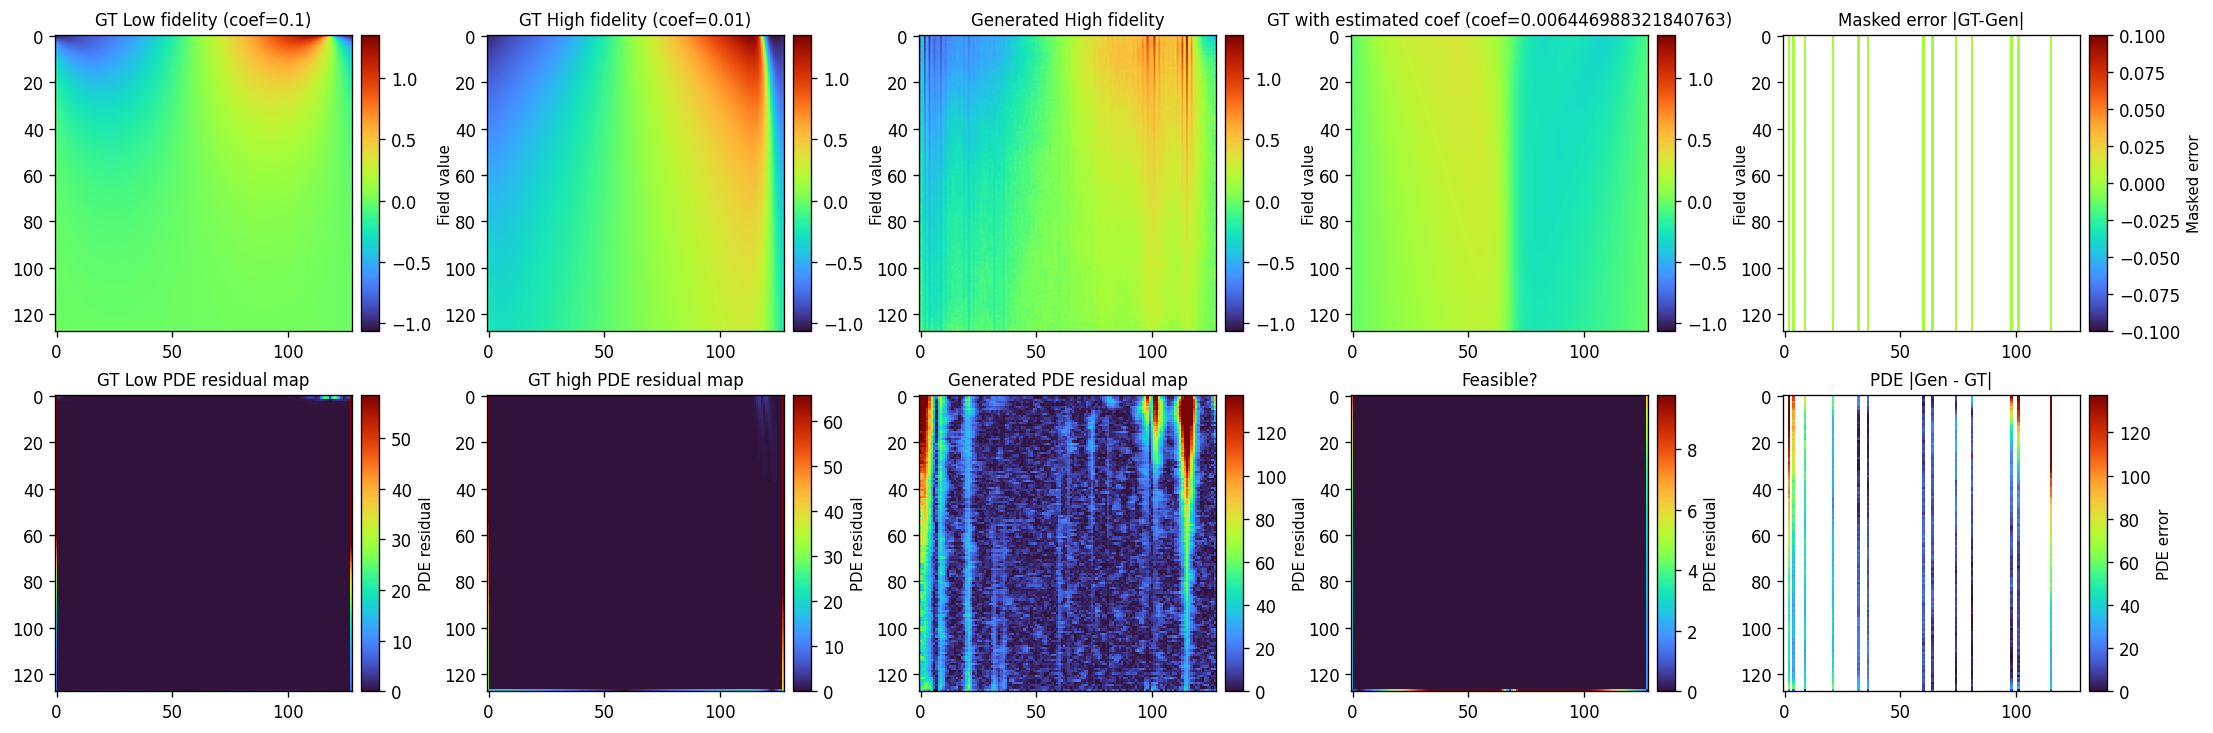

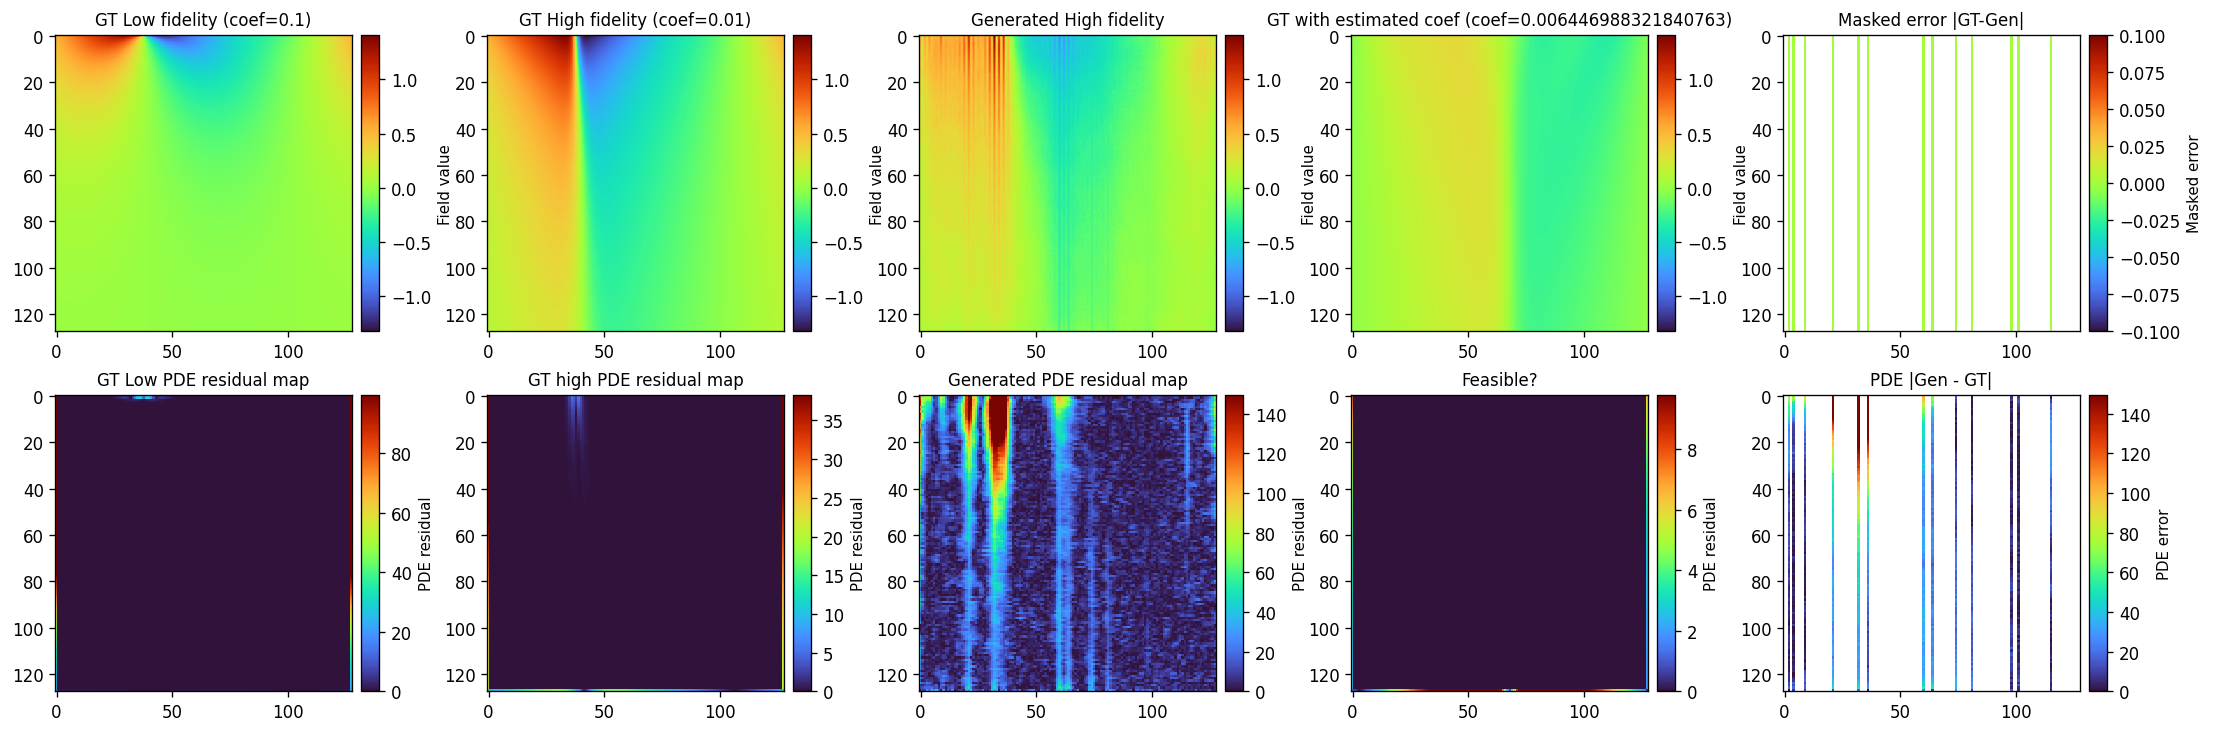

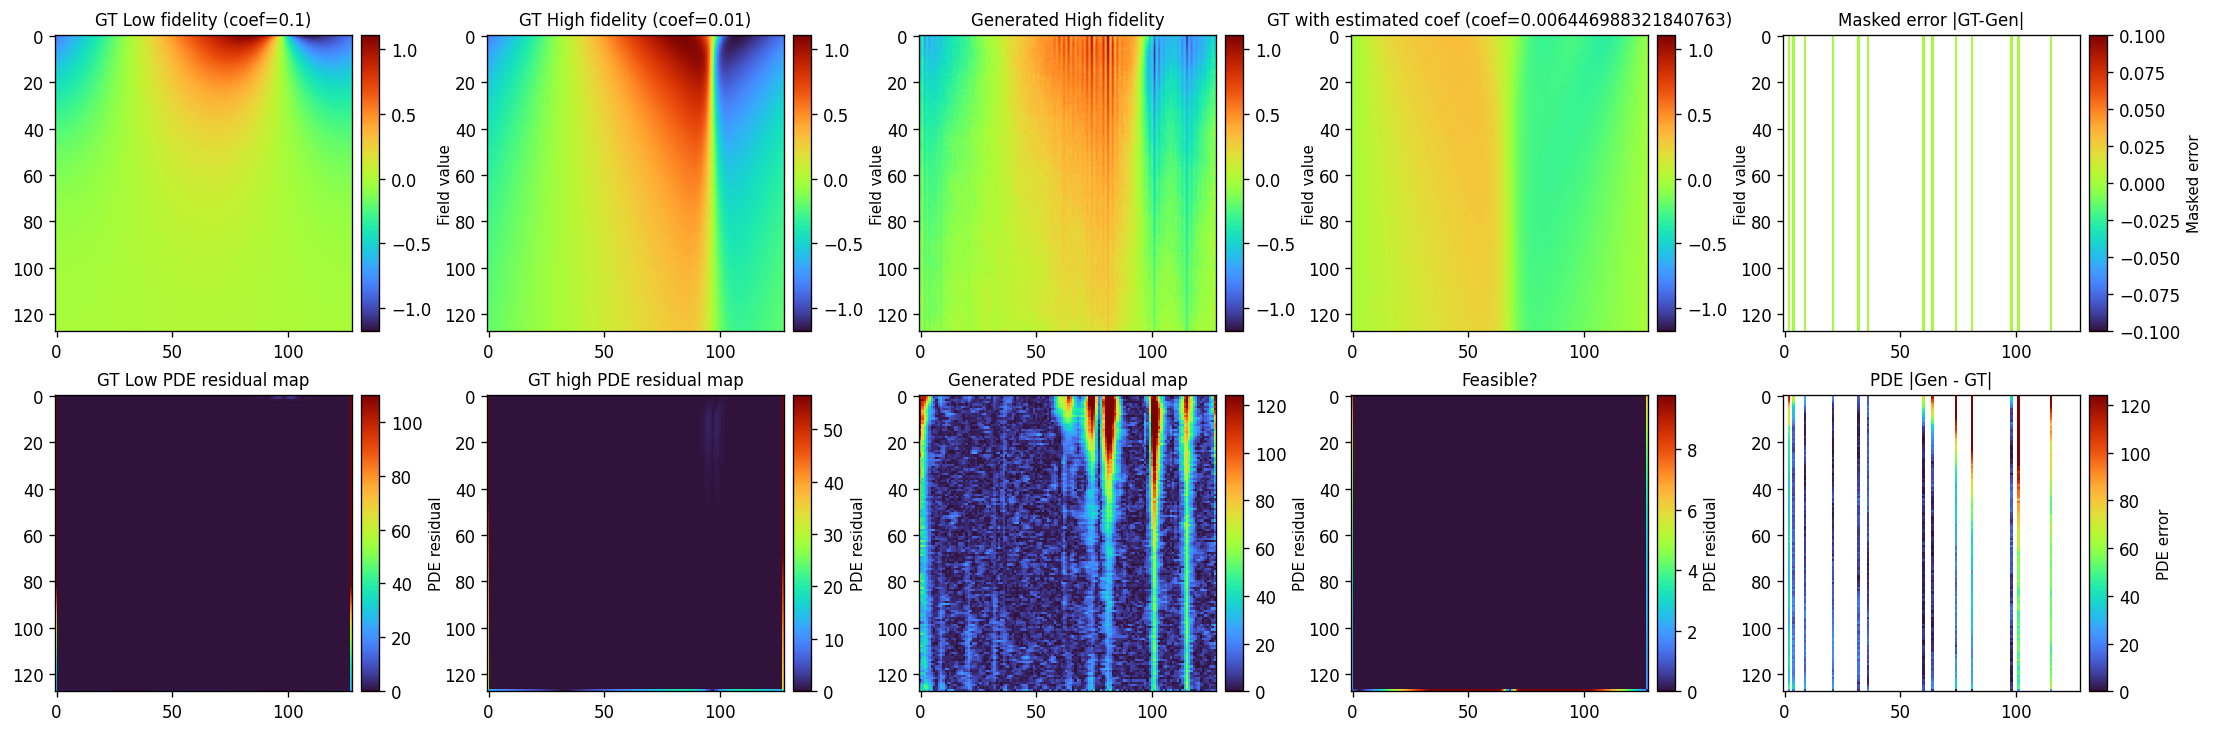

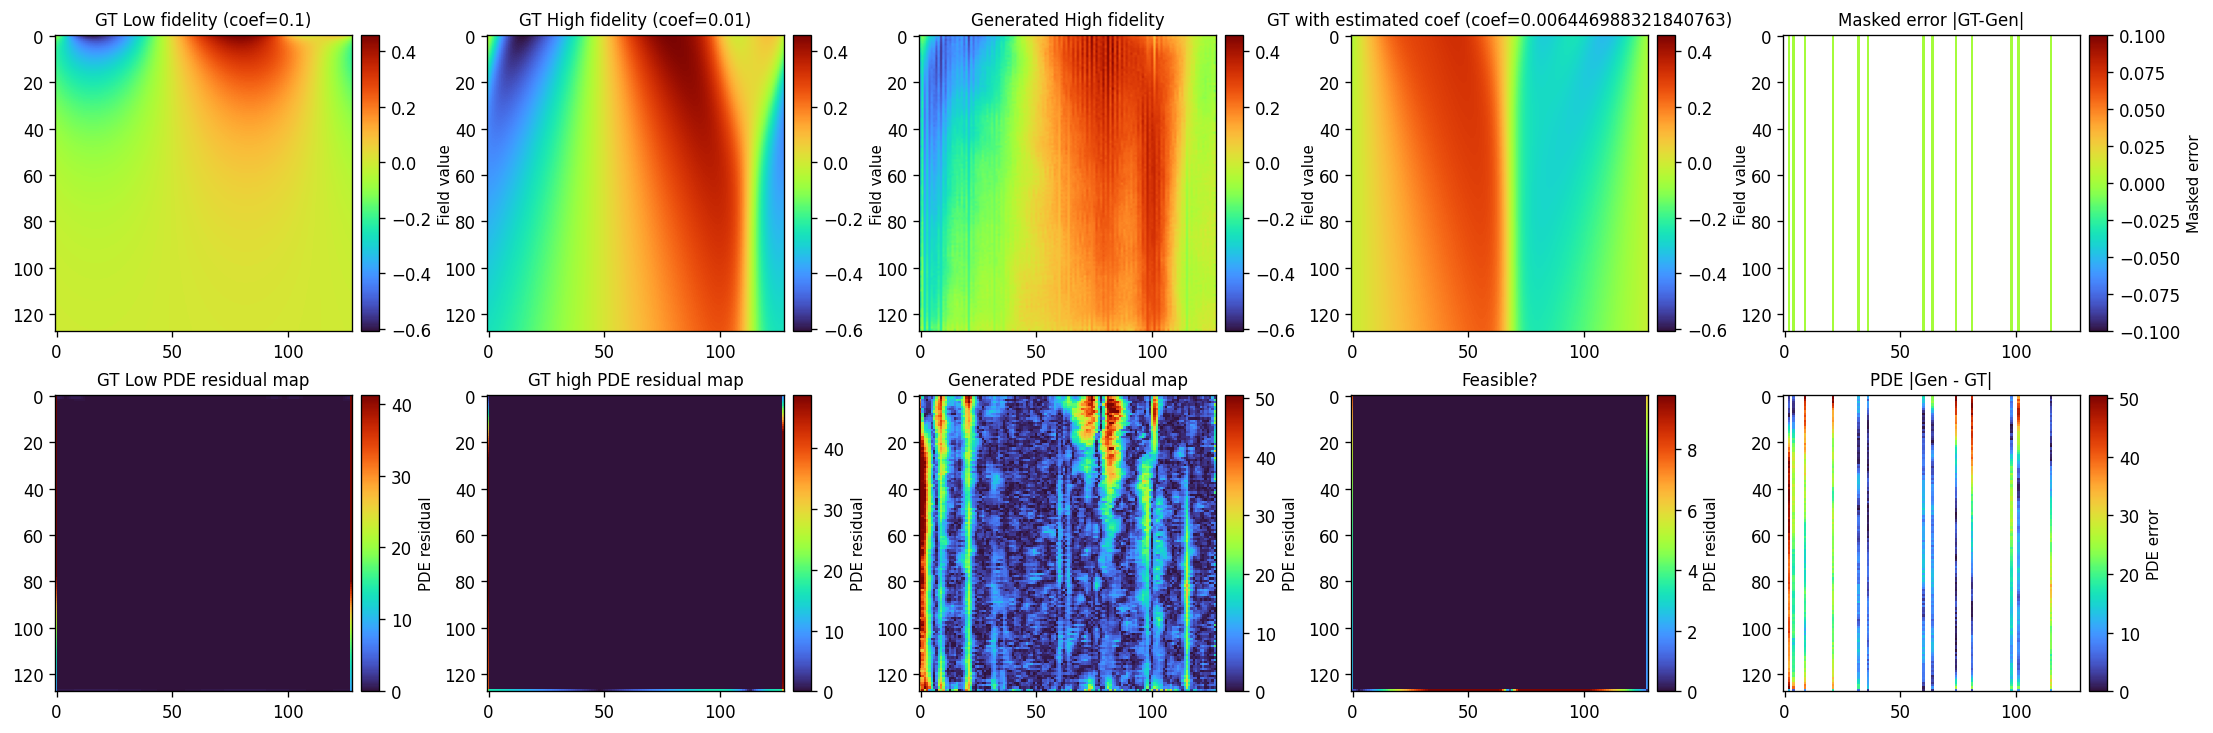

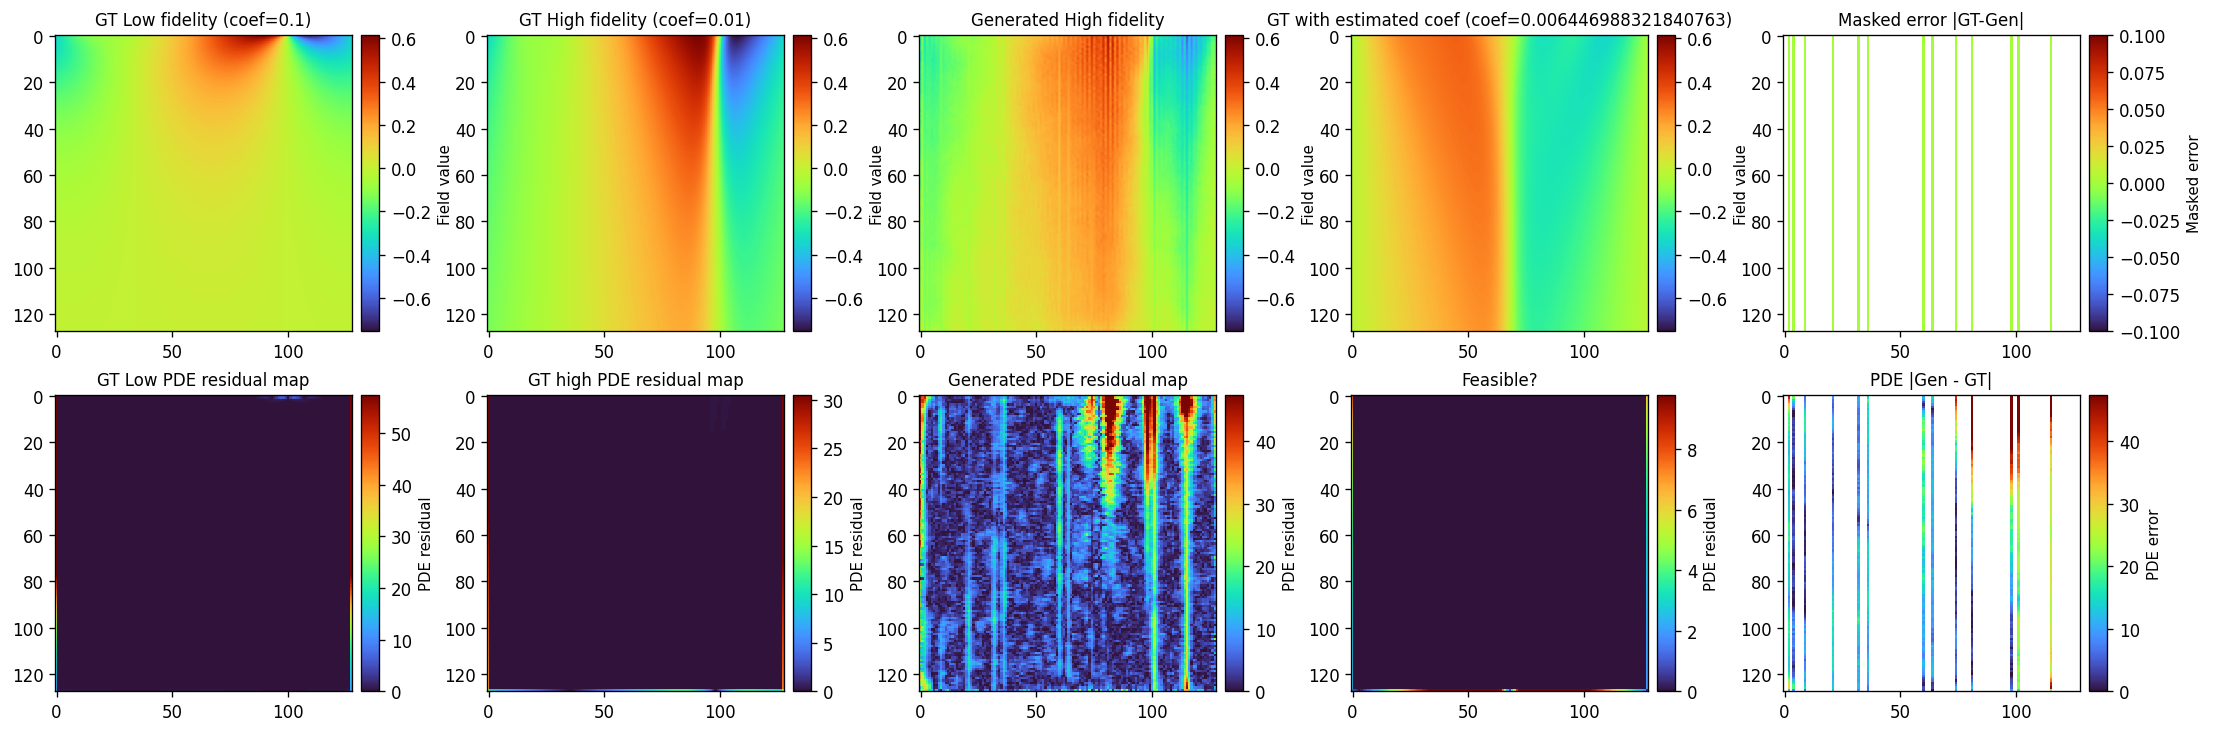

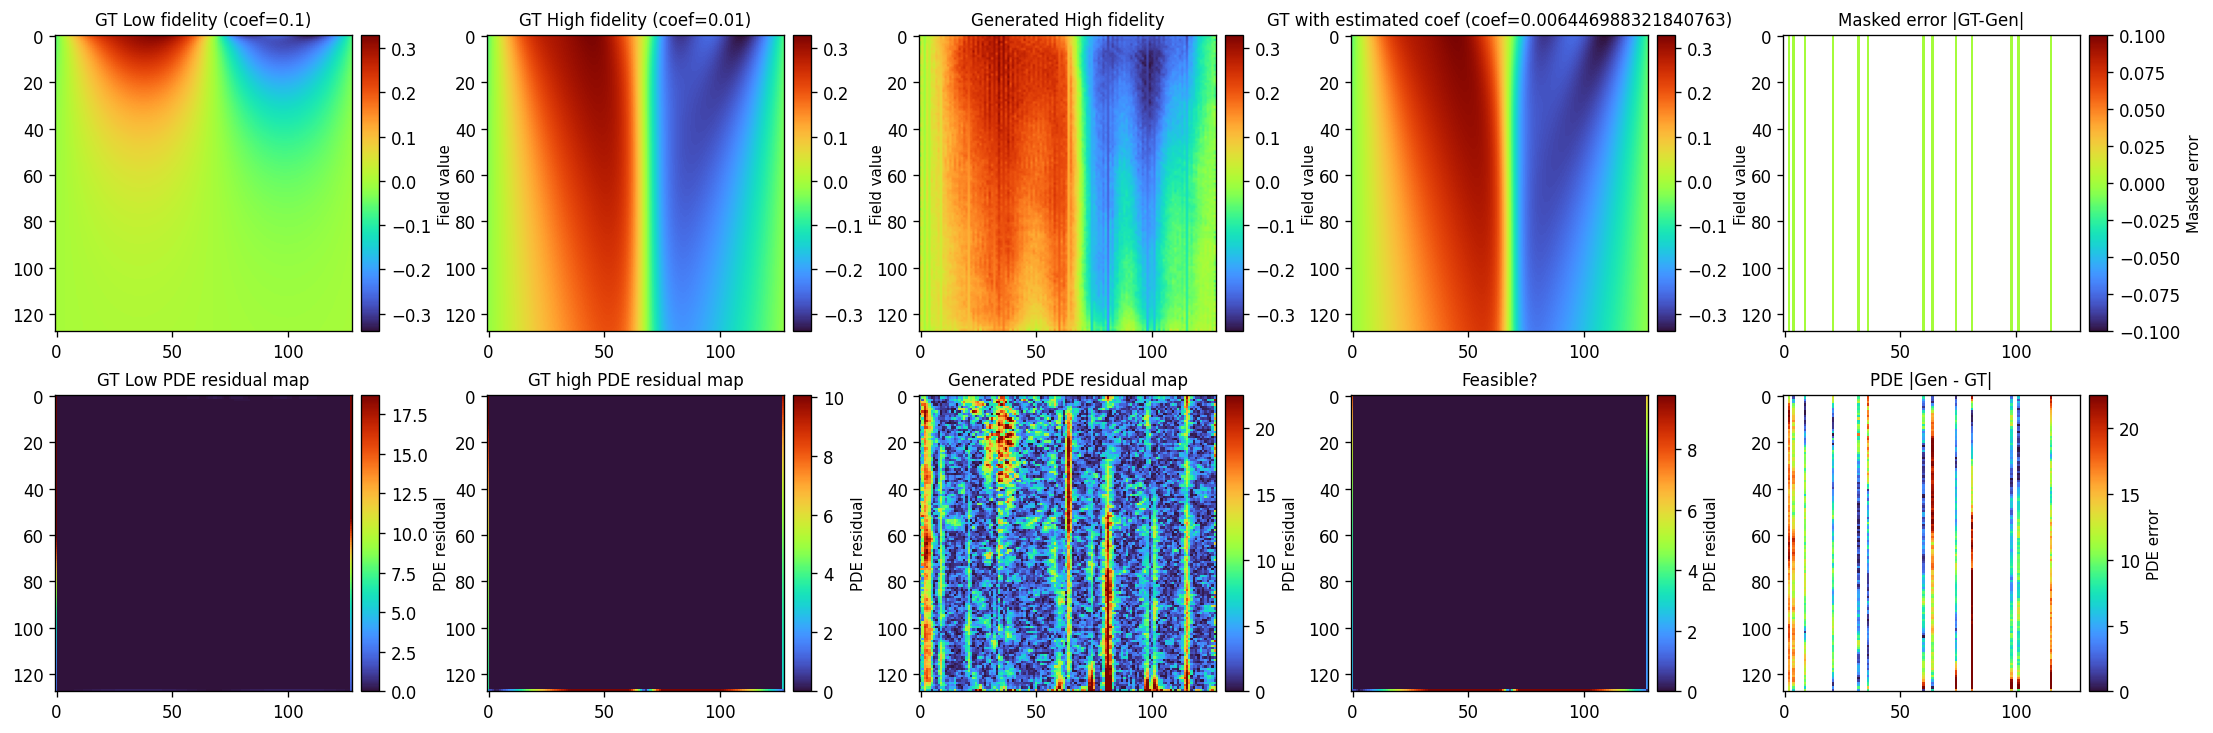

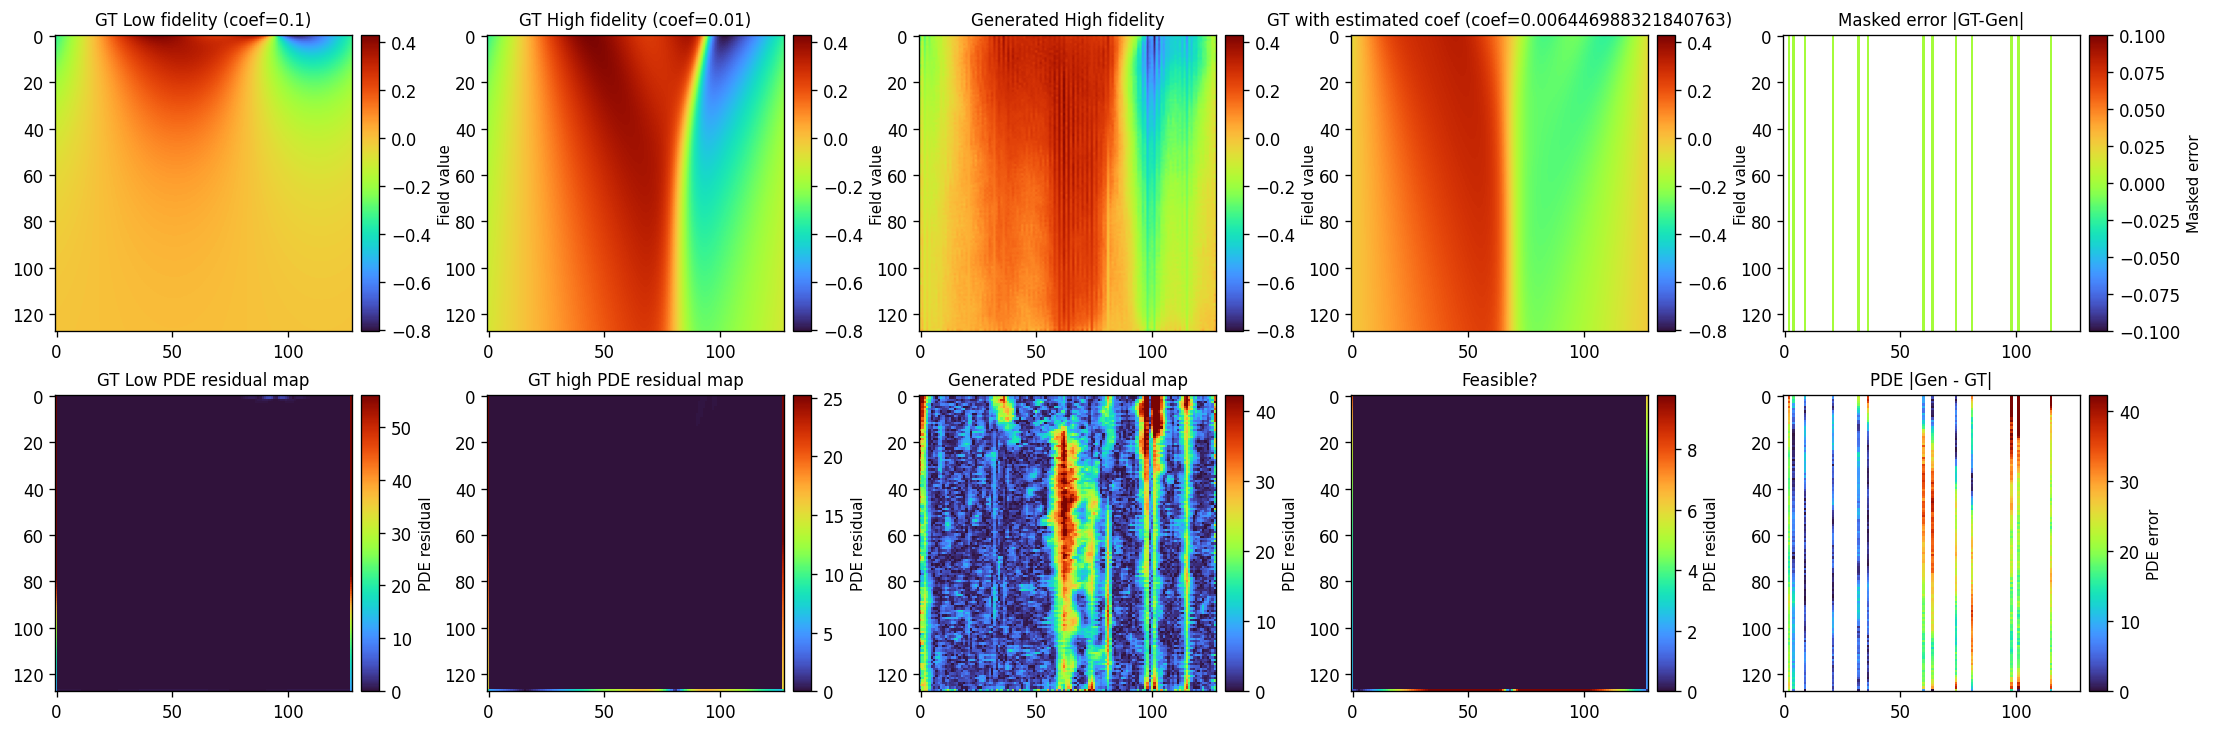

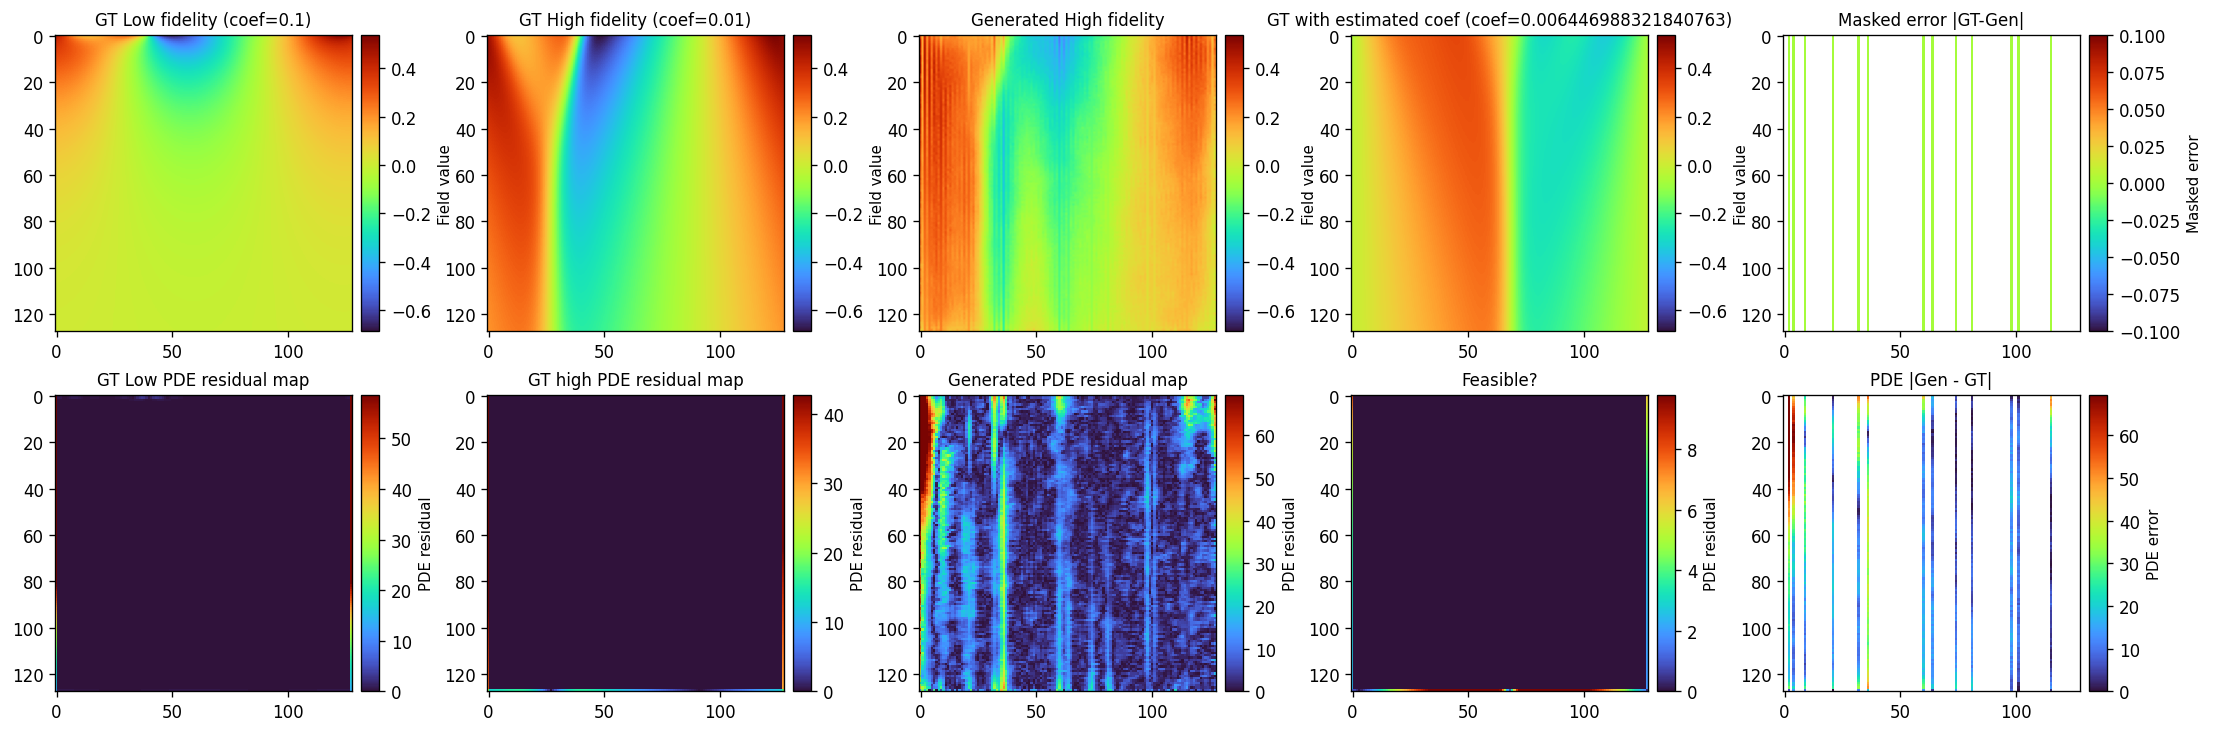

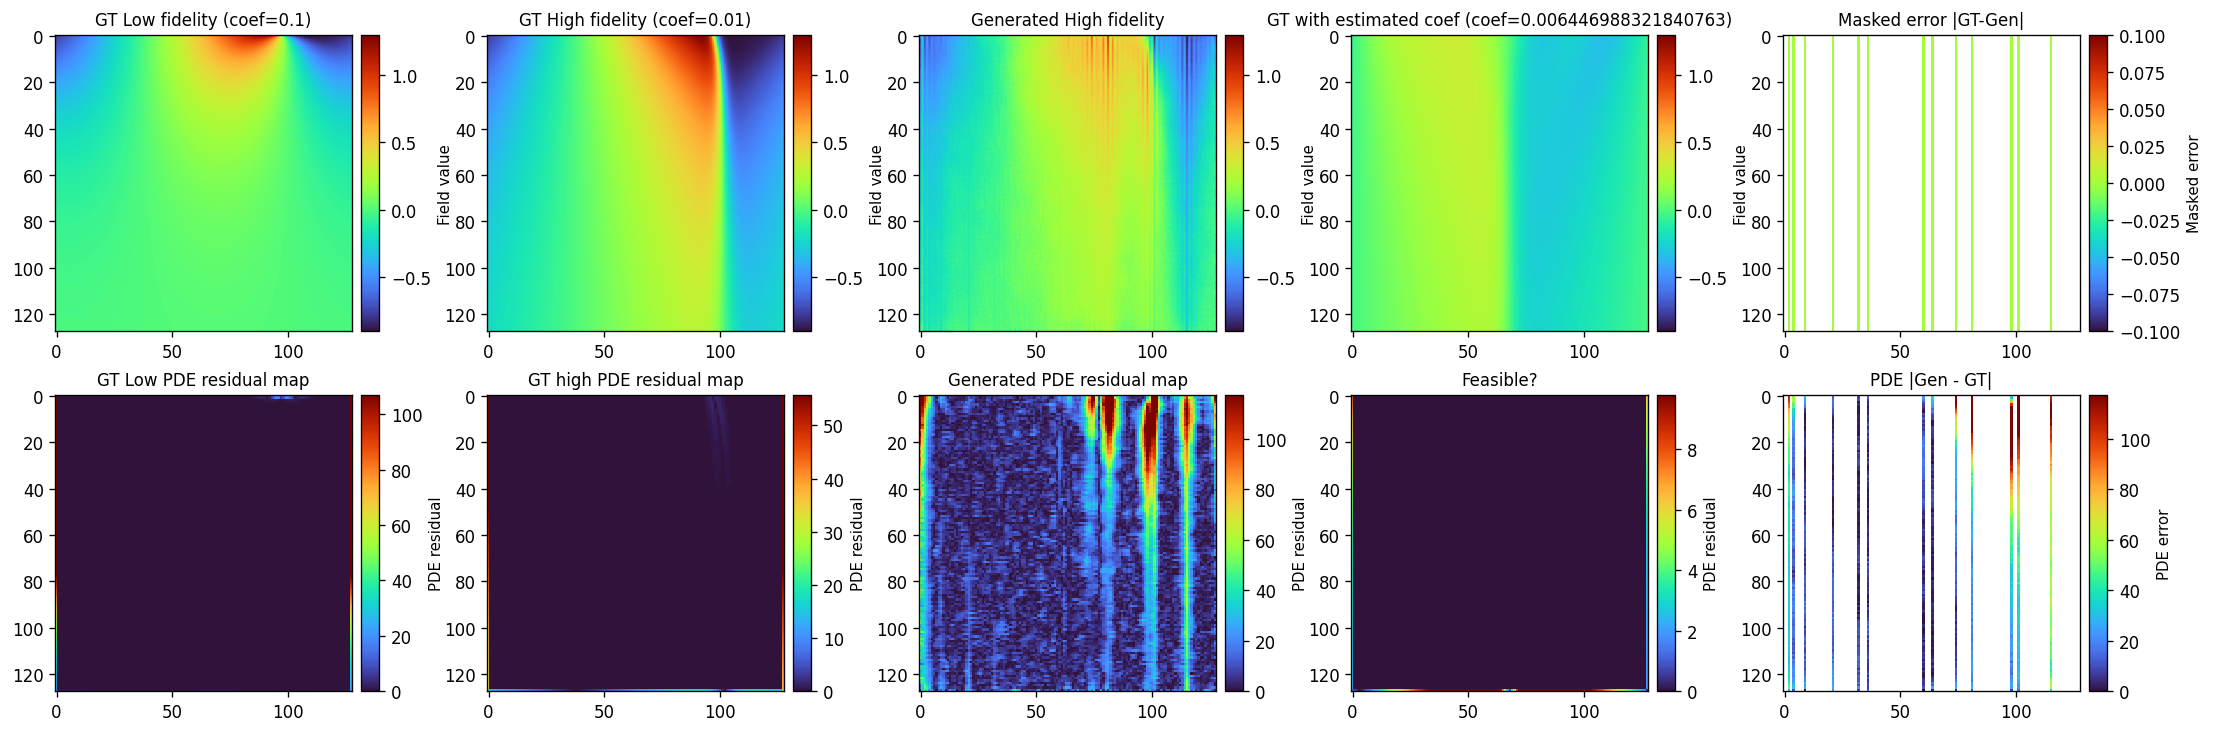

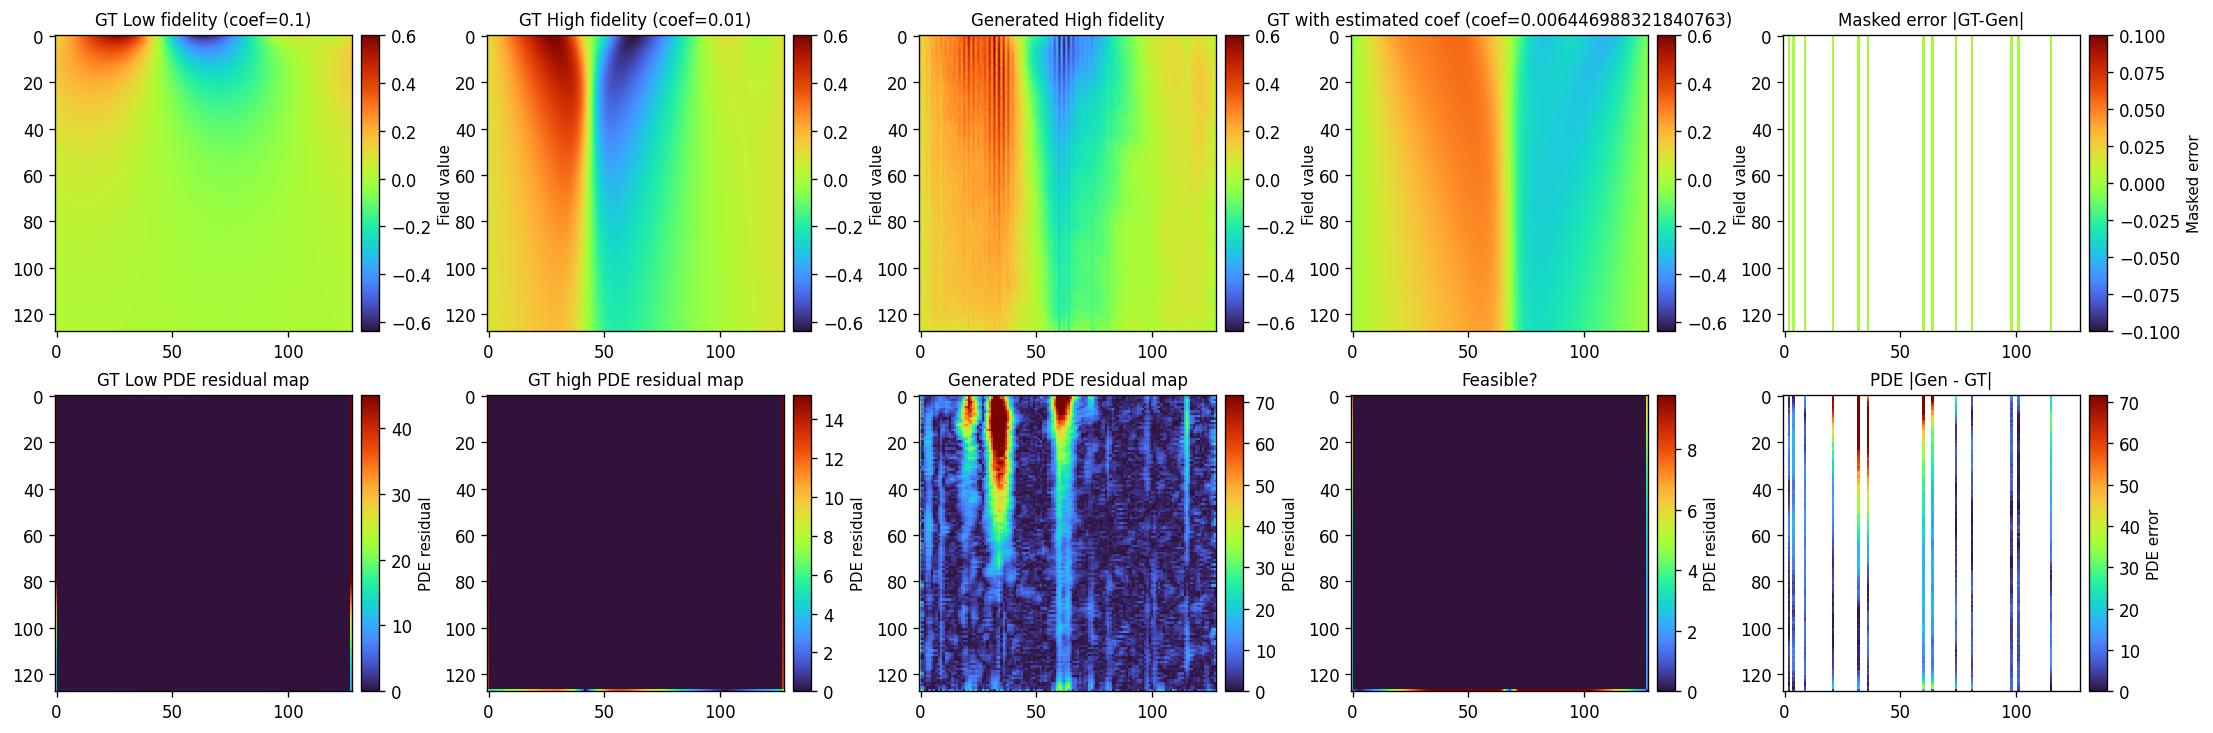

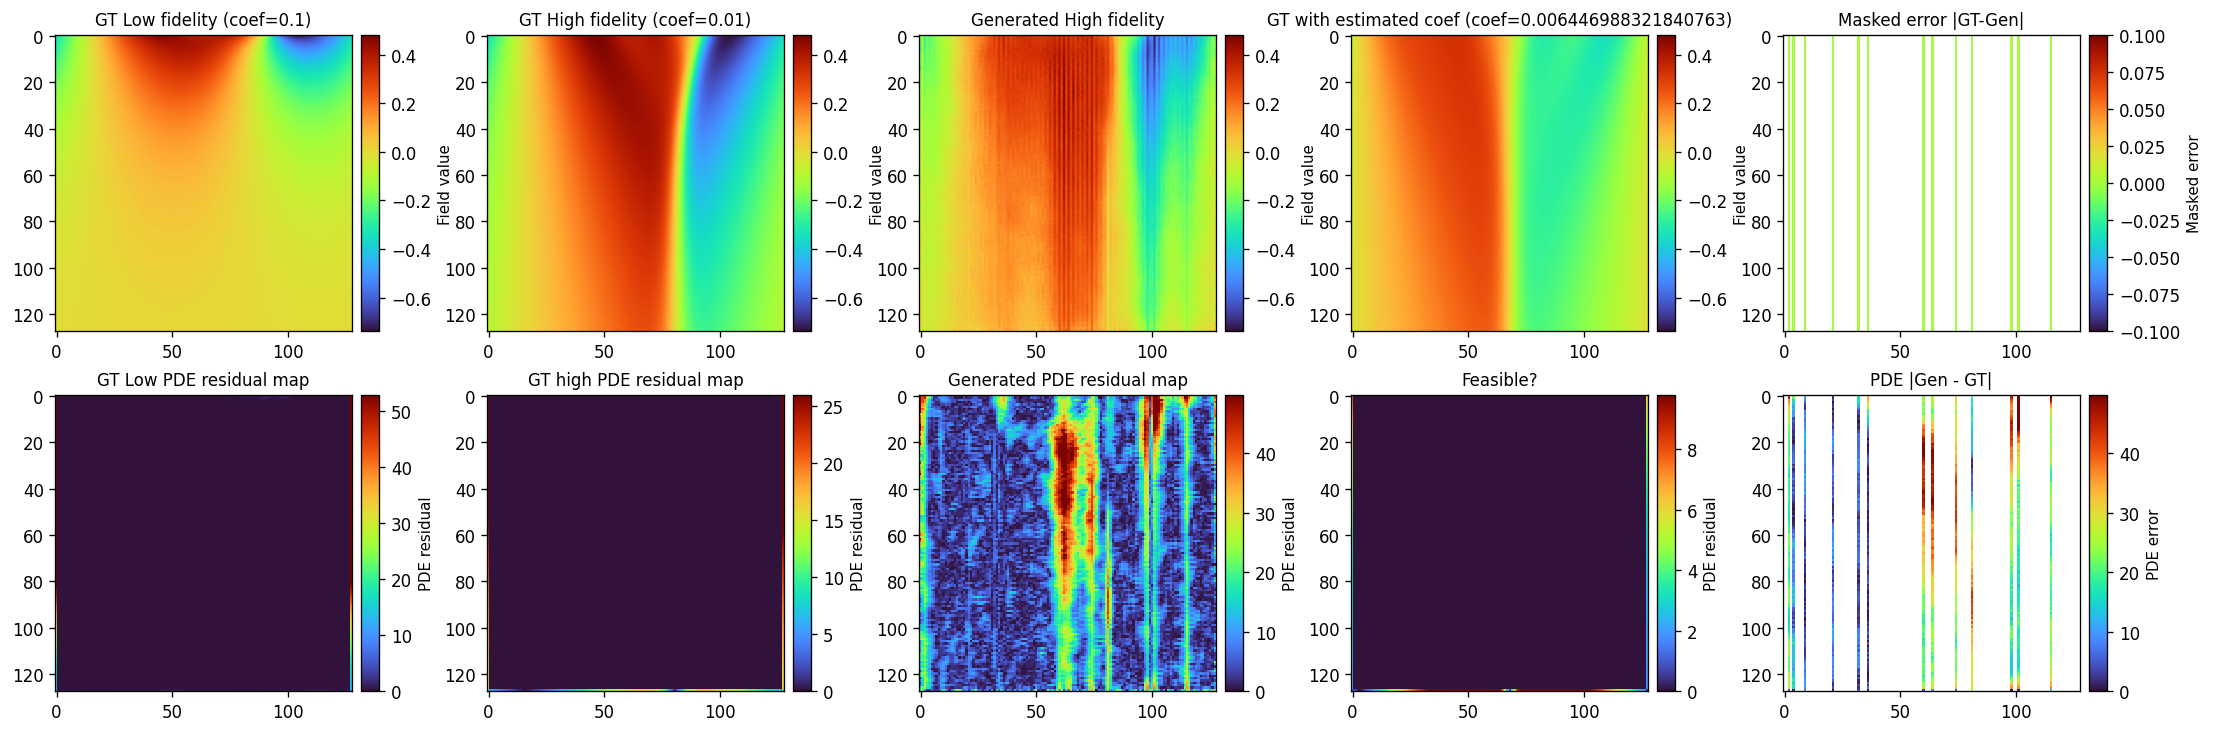

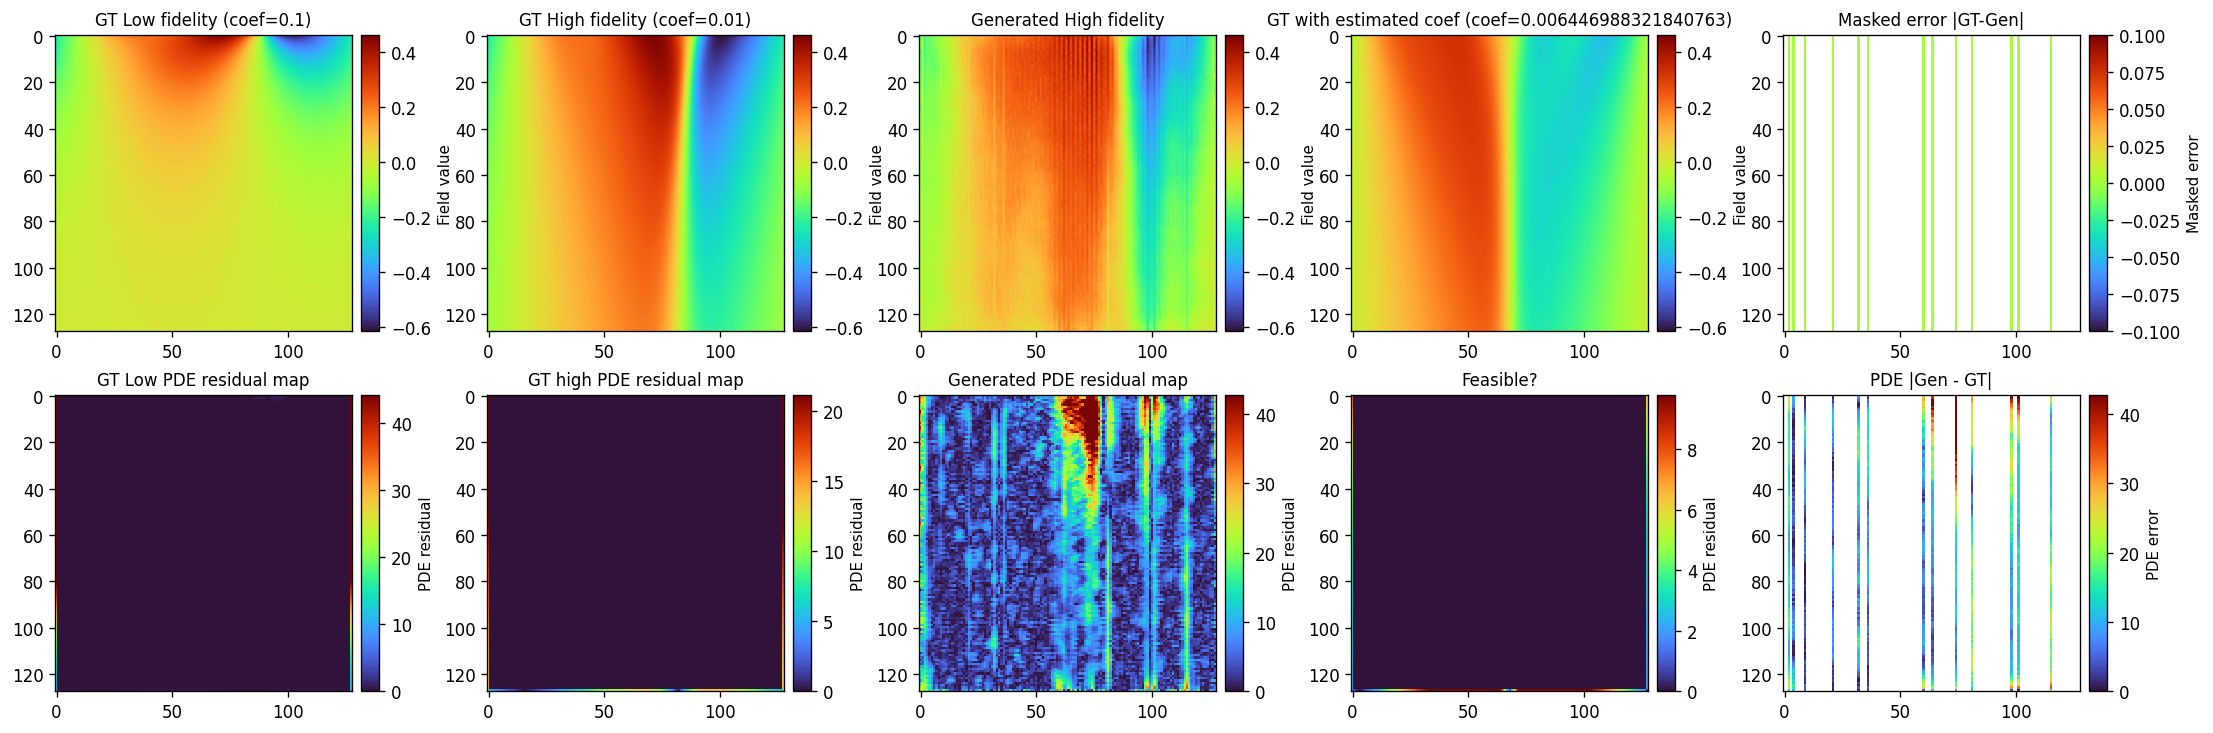

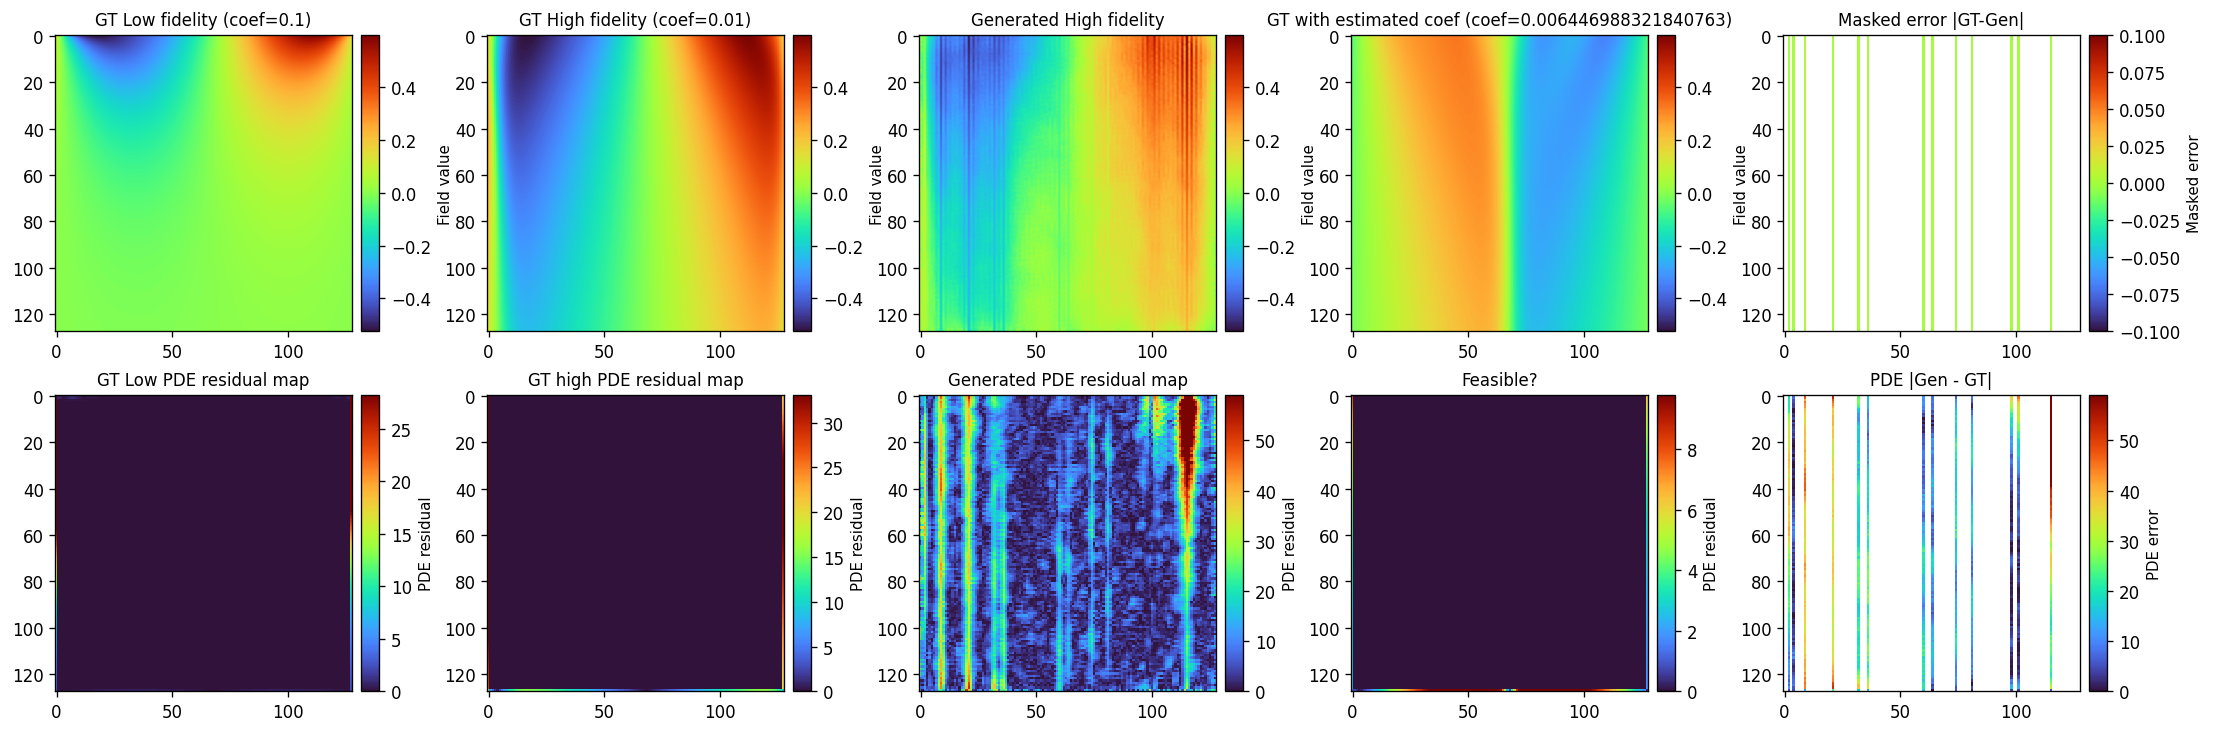

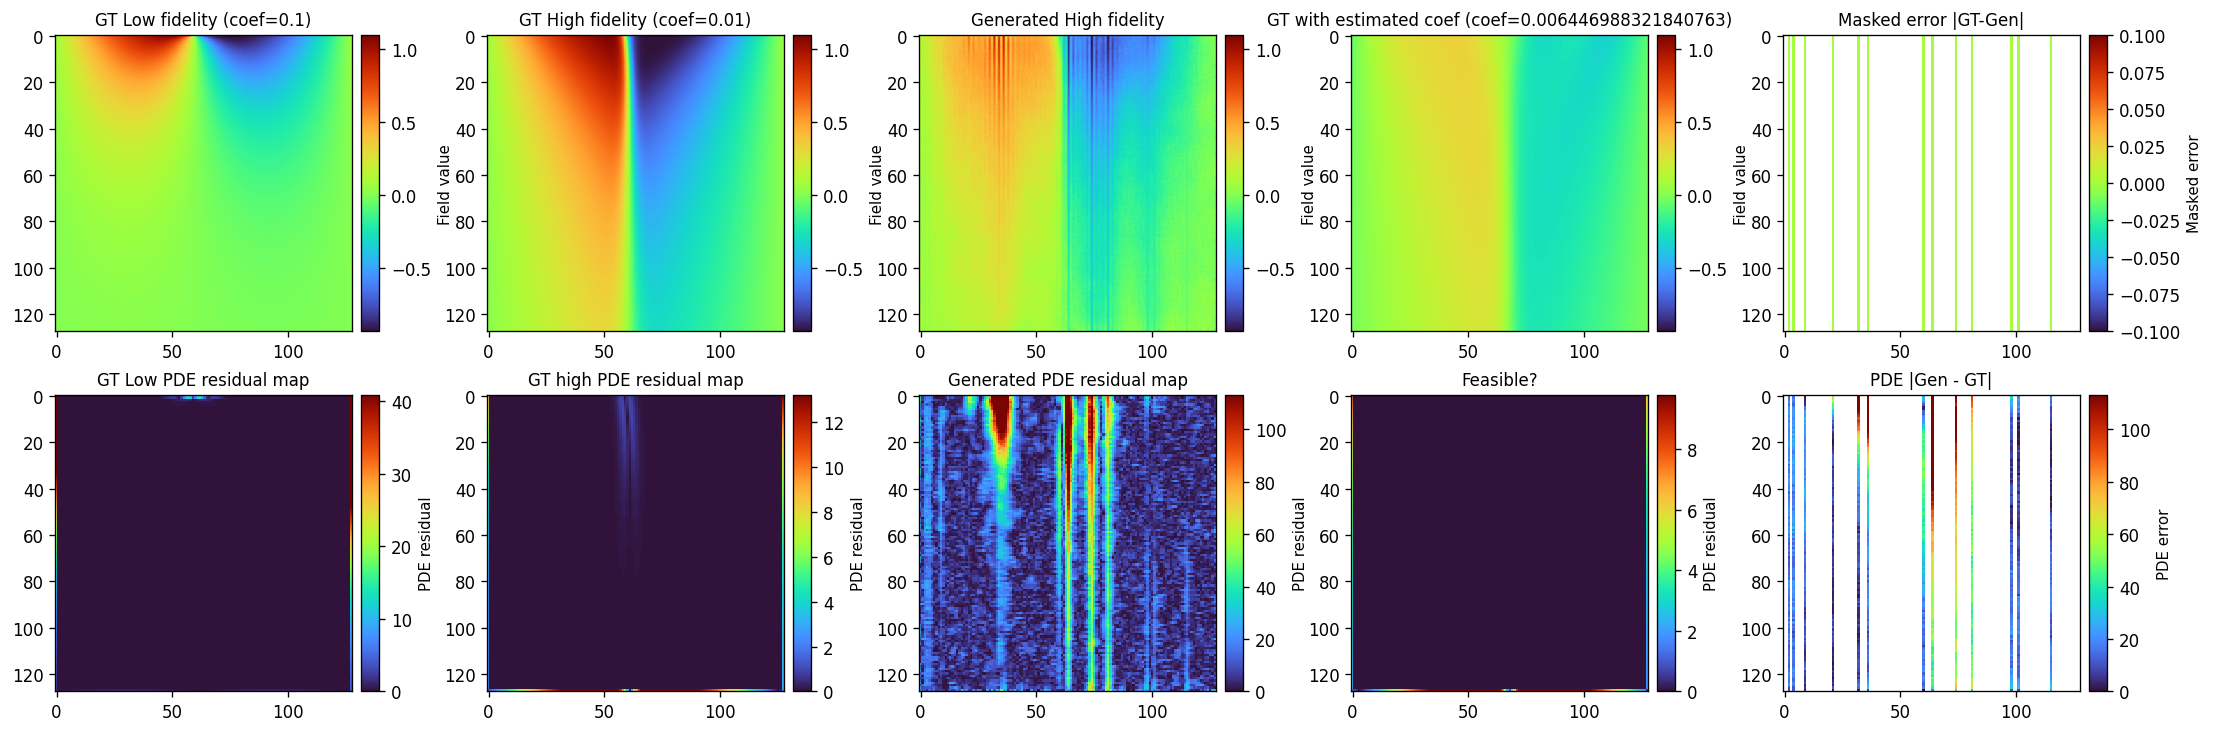

KeyboardInterrupt: 

In [23]:
for i in range(40):
    plot_result(
        dataA=x0_all[[i]],                  
        dataB=x1_all[[i]],                  
        dataB_predict_initial=x1_predict_initial,
        predict=pred_all[[i]],              
        high_resol_coef=high_resol_coef,
        low_resol_coef=low_resol_coef,
        estimated_coef = estimated_coef,
        mask_2d=m1_all[[i]]             
    )